In [2]:
!pip install numpy pandas yfinance scikit-learn tensorflow matplotlib joblib
!pip install pandas-ta --no-deps

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import numpy as np, pandas as pd
import yfinance as yf, pandas_ta as ta
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)

df = yf.download('EURUSD=X', '2000-01-01', '2026-08-31')

# Nettoyage si MultiIndex dans les colonnes (yfinance)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[['Open', 'High', 'Low', 'Close', 'Volume']]
close = df['Close'].squeeze()

df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)

#Features
df['SMA_10'] = ta.sma(close, 10)
df['SMA_20'] = ta.sma(close, 20)
df['EMA_10'] = ta.ema(close, 10)
df['RSI']    = ta.rsi(close, 14)

# MACD
macd = ta.macd(close)
df['MACD']   = macd.iloc[:, 0]  # Ligne MACD
df['MACD_S'] = macd.iloc[:, 2]  # Ligne Signal

# Bandes de Bollinger (Sélection par position iloc pour éviter KeyError)
bb = ta.bbands(close, length=20, std=2)
lower_band = bb.iloc[:, 0]  # Première colonne (Lower Band)
upper_band = bb.iloc[:, -1] # Dernière colonne (Upper Band)
df['BB_WD']  = (upper_band - lower_band) / df['Close']

# Features complémentaires (Ret_1d et ATR)
df['Ret_1d'] = df['Close'].pct_change()
df['ATR']    = ta.atr(df['High'].squeeze(), df['Low'].squeeze(), close, length=14)

# Nettoyage des valeurs NaN générées par les indicateurs
df.dropna(inplace=True)

FEATURES = ['SMA_10', 'SMA_20', 'EMA_10', 'RSI',
            'MACD', 'MACD_S', 'BB_WD', 'Ret_1d', 'ATR']

X = df[FEATURES].values
y = df['Target'].values

split = int(len(X) * 0.8)
Xtr_raw, Xte_raw = X[:split], X[split:]
ytr_raw, yte_raw = y[:split], y[split:]

sc = MinMaxScaler()
Xtr_sc = sc.fit_transform(Xtr_raw)
Xte_sc = sc.transform(Xte_raw)

LOOKBACK = 60

def make_seq(X, y, lb):
    Xs, ys = [], []
    for i in range(lb, len(X)):
        Xs.append(X[i-lb:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

Xtr, ytr = make_seq(Xtr_sc, ytr_raw, LOOKBACK)
Xte, yte = make_seq(Xte_sc, yte_raw, LOOKBACK)

[*********************100%***********************]  1 of 1 completed


In [17]:
# ── STEP 2 : Architecture LSTM ─────────────────────
n_feat = Xtr.shape[2]    # 9 features
lb     = Xtr.shape[1]    # 60 timesteps

model = keras.Sequential([
  layers.LSTM(128, return_sequences=True, input_shape=(lb, n_feat)),
  layers.Dropout(0.3),
  layers.LSTM(64, return_sequences=False),
  layers.Dropout(0.3),
  # Couches denses
  layers.Dense(32, activation='relu'),
  layers.Dropout(0.2),
  # Sortie binaire
  layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-7, verbose=1),
    ModelCheckpoint('best_lstm_eurusd.keras', monitor='val_loss', save_best_only=True),
]

history = model.fit(
    Xtr, ytr,
    epochs           = 150,
    batch_size       = 64,
    validation_split = 0.2,
    callbacks        = callbacks,
    verbose          = 1
)

loss, acc = model.evaluate(Xte, yte, verbose=0)

Epoch 1/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.4955 - loss: 0.6953 - val_accuracy: 0.4908 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 2/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.5069 - loss: 0.6943 - val_accuracy: 0.5059 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 3/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.5069 - loss: 0.6941 - val_accuracy: 0.4951 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 4/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.4918 - loss: 0.6944 - val_accuracy: 0.5027 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 5/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.4982 - loss: 0.6934 - val_accuracy: 0.5027 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 6/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.4899 - loss: 0.6939 - val_accuracy: 0.5027 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 7/150
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.5039 - loss: 0.6932 - 

35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
              precision    recall  f1-score   support

      BAISSE       0.51      1.00      0.68       573
      HAUSSE       0.00      0.00      0.00       541

    accuracy                           0.51      1114
   macro avg       0.26      0.50      0.34      1114
weighted avg       0.26      0.51      0.35      1114

AUC-ROC: 0.4860


C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

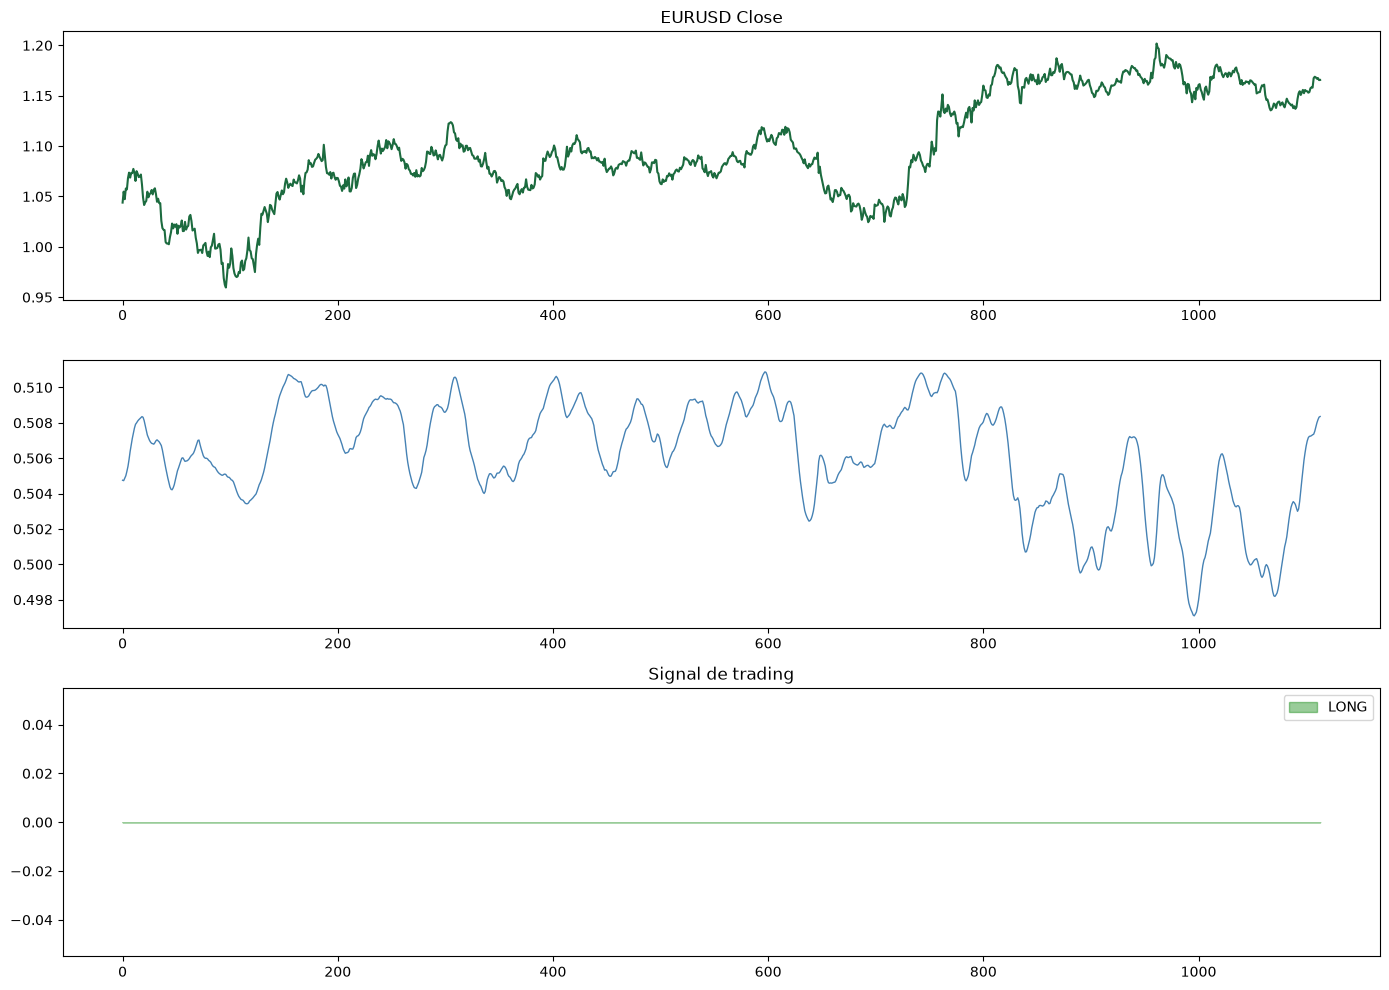

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score

#Prédictions 
y_proba = model.predict(Xte).flatten()
y_pred  = (y_proba >= 0.52).astype(int)  # seuil ajusté

#Rapport de classification
print(classification_report(yte, y_pred,
      target_names=['BAISSE','HAUSSE']))
print(f'AUC-ROC: {roc_auc_score(yte, y_proba):.4f}')

#Visualiser probabilités vs réalité
fig, axes = plt.subplots(3,1,figsize=(14,10))

# Prix EURUSD
close_test = df['Close'].values[split+LOOKBACK:]
axes[0].plot(close_test, lw=1.5, color='#1C6B3F')
axes[0].set_title('EURUSD Close')

# Probabilité HAUSSE
axes[1].plot(y_proba, lw=1, color='steelblue')

# Signal LONG / FLAT
axes[2].fill_between(range(len(y_pred)),
    y_pred, alpha=0.4, color='green', label='LONG')
axes[2].set_title('Signal de trading')
axes[2].legend()
plt.tight_layout(); plt.show()

#Backtesting rapide
ret_daily = pd.Series(close_test).pct_change()
signal    = pd.Series(y_pred).shift(1).fillna(0)
ret_model = signal * ret_daily
ret_bh    = ret_daily

# Déduire les frais
fee = 0.0003
trades = signal.diff().abs()
ret_net = ret_model - trades * fee

cum_bh  =(1+ret_bh.dropna()).cumprod()-1
cum_mdl =(1+ret_net.dropna()).cumprod()-1

In [21]:
import joblib

#Sauvegarder le modèle et le scaler
model.save('lstm_eurusd_final.keras')
joblib.dump(sc, 'scaler_eurusd.pkl')

# Sauvegarder les paramètres importants
params = {
    'lookback' : LOOKBACK,
    'features' : FEATURES,
    'threshold': 0.52,
    'trained_on': '2018-01-01 to 2022-12-31',
    'test_accuracy': float(acc),
}

In [22]:
import json
with open('model_params.json','w') as f:
    json.dump(params, f, indent=2)

#Recharger en production
model2 = keras.models.load_model('lstm_eurusd_final.keras')
sc2    = joblib.load('scaler_eurusd.pkl')

# Pipeline de prédiction quotidienne
def predict_tomorrow(ticker='EURUSD=X'):
    """
    Télécharge les 90 derniers jours,
    calcule les features et retourne
    le signal pour demain.
    """
    # Charger modèle et scaler
    model = keras.models.load_model(
        'lstm_eurusd_final.keras')
    sc    = joblib.load('scaler_eurusd.pkl')
    lb    = LOOKBACK

    # Données récentes (besoin lb+buffer jours)
    df_live = yf.download(ticker, period='120d')

    # Features
    df_live['SMA_10']=ta.sma(df_live['Close'],10)
    df_live['RSI']   =ta.rsi(df_live['Close'],14)
    # ... autres features ...
    df_live.dropna(inplace=True)